# figures_5clusters.ipynb

Reproduces the main paper analysis ([`figures_paper.ipynb`](figures_paper.ipynb)) on the
**5-state** VAE-HMM model (`exp_20260223_1140_5c129e`, `latent_dim=8`, `hidden_dim=512`,
`num_states=5`) instead of the 7-state paper model. Same VAE backbone, fewer HMM states.

We ask whether the four headline results survive coarsening to 5 clusters:

1. **Main axis of variability** — do we still recover the precipitation / organization plane (Q1)?
2. **Organized cluster** — is there an organized cluster, and does its vertical mass-flux profile support that reading (Q2)?
3. **Eigenvectors** — is the leading non-stationary mode (λ₂) still a *two-regime* split (Q3)?
4. **Non-Markovianity** — does the organized cluster still decay more slowly than the Markov prediction (Q4)?

Shared utilities come from [`workflow_paper.py`](../workflow_paper.py); we only override
`MODEL_PATH`, `NUM_STATES`, and the colour palette for 5 states. Figures are written to a
separate `figures_5clusters/` folder so the manuscript figures are never touched.

## 1 · Imports & 5-state reconfiguration

In [1]:
import sys
sys.path.insert(0, '/Users/sophieabramian/Documents/troposwhere/paper')

import os
import importlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, Normalize as Norm
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter1d

import workflow_paper as wfp
importlib.reload(wfp)

# ── Point the shared module at the 5-state model ────────────────────────────
NUM_STATES     = 5
wfp.NUM_STATES = NUM_STATES
wfp.MODEL_PATH = ('/Users/sophieabramian/Documents/troposwhere/data/runs/'
                  'exp_20260223_1140_5c129e/best_model.pt')

# ── 5-colour palette (rebuilt; wfp's default is 7 colours) ──────────────────
palette_5 = ['#1e78b3', '#e02222', '#bcbcdd', '#ffe066', '#5ec962']
state_colors = np.array(palette_5)
cluster_cmap = ListedColormap(state_colors)
norm_state   = Norm(vmin=0, vmax=NUM_STATES - 1)
# keep wfp's copies consistent in case any helper reads them
wfp.state_colors, wfp.cluster_cmap, wfp.norm_state = state_colors, cluster_cmap, norm_state

# Output folder (kept separate from the manuscript figures/)
path_save_fig = '/Users/sophieabramian/Documents/troposwhere/paper/notebooks/figures_5clusters'
os.makedirs(path_save_fig, exist_ok=True)

print('LATENT_DIM', wfp.LATENT_DIM, '| HIDDEN_DIM', wfp.HIDDEN_DIM, '| NUM_STATES', wfp.NUM_STATES)
print('model:', os.path.basename(os.path.dirname(wfp.MODEL_PATH)))

LATENT_DIM 8 | HIDDEN_DIM 512 | NUM_STATES 5
model: exp_20260223_1140_5c129e


## 2 · Data loading

Run model inference on the full dataset, load diagnostics, and pre-compute the transition
matrix, stationary distribution, and indicator autocorrelations — everything reused below.

In [2]:
# ── Model & latents ─────────────────────────────────────────────────────────
loader, input_dim     = wfp.load_dataloader()
model                 = wfp.load_model(input_dim=input_dim)
out                   = wfp.extract_latents(model, loader)
embeddings            = out["embeddings"]
states                = out["states"]
emb_pca, pca          = wfp.run_pca(embeddings)
_, state_keep_indices = wfp.keep_closest_latent_samples(embeddings, states)

# ── Diagnostics ──────────────────────────────────────────────────────────────
mass_flux = np.load(wfp.PATHS["data_raw"])[:-1]
z_array   = wfp.load_z_array()
s_array   = np.linspace(320, 350, 48)
pw        = np.load(wfp.PATHS["pw"])[:len(states)]
prec      = np.load(wfp.PATHS["prec"])[:len(states)]
pw_norm   = Norm(vmin=1, vmax=17)
prec_norm = Norm(vmin=0, vmax=6)

# Align mass_flux to embedding length (local data may be shorter)
n = min(len(mass_flux), len(embeddings))
mass_flux = mass_flux[:n]
state_keep_indices_mf = {
    s: idxs[idxs < n]
    for s, idxs in state_keep_indices.items()
    if (idxs < n).any()
}

# ── Transition analysis (global, unconditional chain) ────────────────────────
Tmat   = wfp.compute_transition_matrix(states, NUM_STATES, future=5)
pi     = wfp.stationary_distribution(Tmat)
C_obs  = wfp.indicator_autocorrelation_normalized(states[::5], max_lag=50)
C_markov_per_state = np.array([
    wfp.markov_autocorrelation_indicator(Tmat, pi, state_idx=s, max_lag=50)
    for s in range(NUM_STATES)
])

unique, counts = np.unique(states, return_counts=True)
print('N timesteps:', len(states), '| input_dim:', input_dim)
print('cluster counts:', dict(zip(unique.tolist(), counts.tolist())))
print('PCA explained variance ratio (PC1, PC2):', np.round(pca.explained_variance_ratio_[:2], 3))

N timesteps: 19475 | input_dim: 1560
cluster counts: {0: 2560, 1: 2376, 2: 7236, 3: 4381, 4: 2922}
PCA explained variance ratio (PC1, PC2): [0.226 0.182]


## 2b · Cluster fingerprint table

Mean precipitation, PW index, and PCA coordinates per cluster — used throughout to label
which cluster is "organized". We pick the organized cluster automatically as the one with the
highest PW index (the moist, mesoscale-organized signature), and the most intense as the one
with the highest mean precipitation.

In [3]:
print(f"{'cluster':>8} {'n':>6} {'mean_prec':>10} {'mean_PW':>9} {'PCA1':>8} {'PCA2':>8}")
print('-' * 56)
fingerprint = {}
for s in range(NUM_STATES):
    m = states == s
    row = dict(n=int(m.sum()), prec=prec[m].mean(), pw=pw[m].mean(),
               pca1=emb_pca[m, 0].mean(), pca2=emb_pca[m, 1].mean())
    fingerprint[s] = row
    print(f"{wfp.state_label(s):>8} {row['n']:>6} {row['prec']:>10.3f} "
          f"{row['pw']:>9.3f} {row['pca1']:>+8.3f} {row['pca2']:>+8.3f}")

ORG_STATE  = max(range(NUM_STATES), key=lambda s: fingerprint[s]['pw'])    # moist / organized
INT_STATE  = max(range(NUM_STATES), key=lambda s: fingerprint[s]['prec'])  # most intense precip
print(f"\nOrganized cluster (max PW): State {wfp.state_label(ORG_STATE)}")
print(f"Most intense cluster (max precip): State {wfp.state_label(INT_STATE)}")

 cluster      n  mean_prec   mean_PW     PCA1     PCA2
--------------------------------------------------------
       1   2560      4.686    16.855   +0.063   +2.238
       2   2376      4.996     9.843   +1.082   +2.690
       3   7236      1.712     9.415   -2.164   -0.463
       4   4381      4.515     4.033   +2.195   -0.823
       5   2922      2.737     4.226   +1.132   -1.767

Organized cluster (max PW): State 1
Most intense cluster (max precip): State 2


## Q1 · Main axis of variability — precipitation / organization plane

Left: latent PCA scatter coloured by cluster. Right two panels: the same PCA plane coloured by
precipitation and by PW index. If PC1 still tracks intensity (precip) and PC2 tracks
organization (PW), we recover the same plane of variability as the 7-state model.

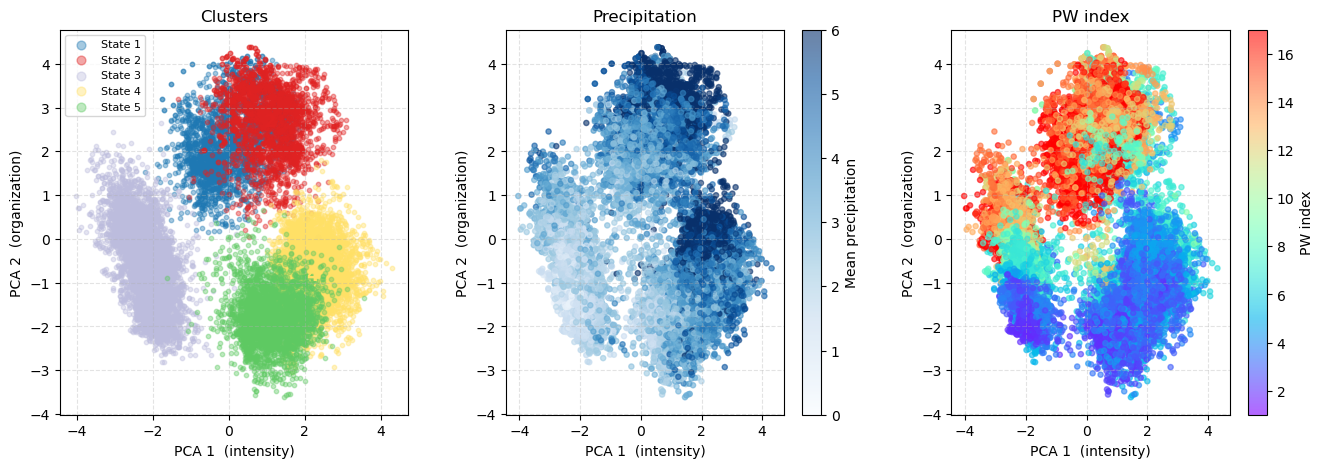

In [4]:
fig = plt.figure(figsize=(16, 5))
gs  = gridspec.GridSpec(1, 3, wspace=0.28)

# (a) clusters
ax0 = fig.add_subplot(gs[0, 0])
for s in range(NUM_STATES):
    pts = emb_pca[states == s]
    ax0.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.4, color=state_colors[s],
                label=f"State {wfp.state_label(s)}")
    bc = pts.mean(axis=0)
    ax0.text(*bc, wfp.state_label(s), fontsize=13, fontweight='bold',
             color=state_colors[s], ha='center', va='center')
ax0.set(xlabel='PCA 1  (intensity)', ylabel='PCA 2  (organization)', title='Clusters')
ax0.legend(fontsize=8, markerscale=2, loc='best')

# (b) coloured by precipitation
ax1 = fig.add_subplot(gs[0, 1])
sc1 = ax1.scatter(emb_pca[:, 0], emb_pca[:, 1], c=prec, cmap='Blues', norm=prec_norm,
                  s=14, alpha=0.6)
ax1.set(xlabel='PCA 1  (intensity)', ylabel='PCA 2  (organization)', title='Precipitation')
fig.colorbar(sc1, ax=ax1, label='Mean precipitation')

# (c) coloured by PW
ax2 = fig.add_subplot(gs[0, 2])
sc2 = ax2.scatter(emb_pca[:, 0], emb_pca[:, 1], c=pw, cmap='rainbow', norm=pw_norm,
                  s=14, alpha=0.6)
ax2.set(xlabel='PCA 1  (intensity)', ylabel='PCA 2  (organization)', title='PW index')
fig.colorbar(sc2, ax=ax2, label='PW index')

for ax in (ax0, ax1, ax2):
    ax.grid(True, linestyle='--', alpha=0.35)
plt.savefig(os.path.join(path_save_fig, 'q1_clusters_axes.pdf'), bbox_inches='tight')
plt.show()

## Q1b · PCA axes vs diagnostics

Quantify the axis interpretation: PCA 1 vs precipitation and PCA 2 vs PW index, coloured by
cluster. Monotonic relations confirm the intensity / organization reading and report the
correlation coefficients.

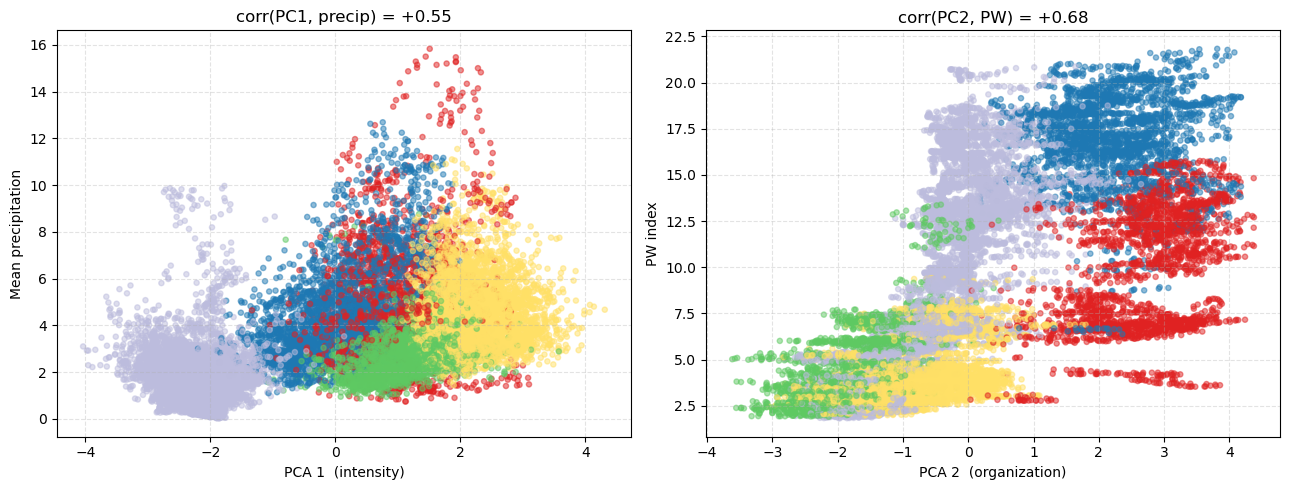

corr(PC1, precip) = +0.553   corr(PC2, PW) = +0.677


In [5]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 5))
axl.scatter(emb_pca[:, 0], prec, c=states, cmap=cluster_cmap, norm=norm_state, s=14, alpha=0.5)
axl.set(xlabel='PCA 1  (intensity)', ylabel='Mean precipitation')
axr.scatter(emb_pca[:, 1], pw, c=states, cmap=cluster_cmap, norm=norm_state, s=14, alpha=0.5)
axr.set(xlabel='PCA 2  (organization)', ylabel='PW index')
for ax in (axl, axr):
    ax.grid(True, linestyle='--', alpha=0.35)

r_pc1_prec = np.corrcoef(emb_pca[:, 0], prec)[0, 1]
r_pc2_pw   = np.corrcoef(emb_pca[:, 1], pw)[0, 1]
axl.set_title(f"corr(PC1, precip) = {r_pc1_prec:+.2f}")
axr.set_title(f"corr(PC2, PW) = {r_pc2_pw:+.2f}")
plt.tight_layout()
plt.savefig(os.path.join(path_save_fig, 'q1b_axis_vs_diagnostics.pdf'), bbox_inches='tight')
plt.show()
print(f"corr(PC1, precip) = {r_pc1_prec:+.3f}   corr(PC2, PW) = {r_pc2_pw:+.3f}")

## Q2 · Organized cluster — vertical structure

Per-cluster anomaly profiles of upward / downward / net mass flux against height (left set) and
against MSE (stacked set). The organized cluster should show a deep, coherent net updraft. Each
curve is the bootstrap mean over the closest-to-centroid samples with a 90% CI band.

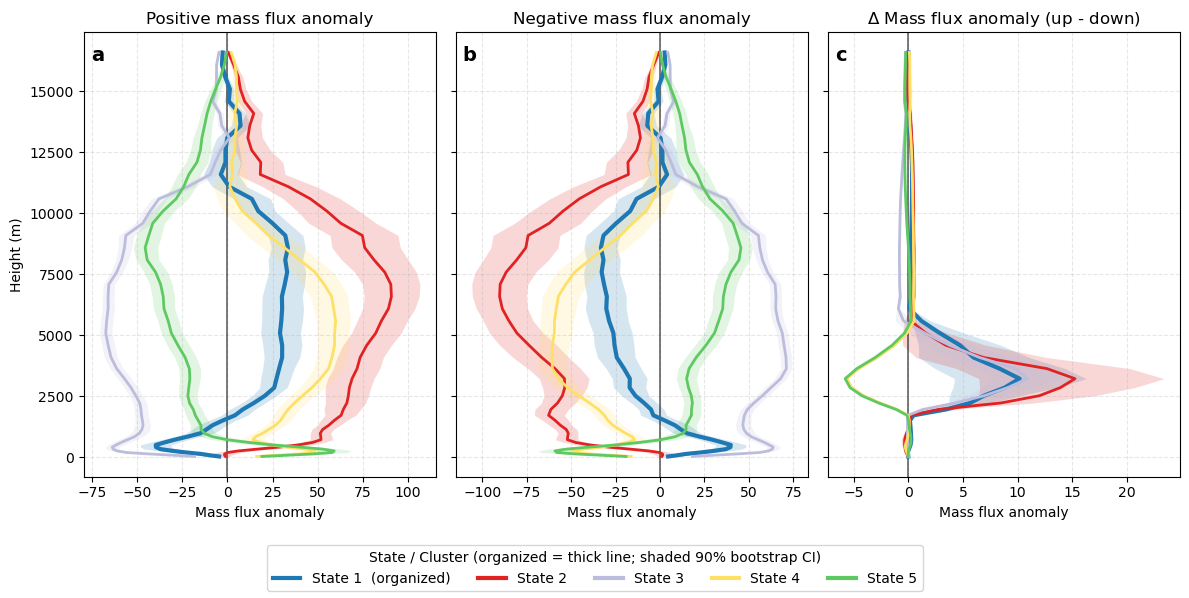

In [6]:
win     = 5
mf_pos  = np.where(mass_flux > 0, mass_flux, 0.0)
mf_neg  = np.where(mass_flux < 0, mass_flux, 0.0)
mf_diff = mf_pos + mf_neg
mf_list = [(mf_pos,  'Positive mass flux anomaly'),
           (mf_neg,  'Negative mass flux anomaly'),
           (mf_diff, r'$\Delta$ Mass flux anomaly (up - down)')]

fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for ax, (mf, title), lbl in zip(axes, mf_list, ['a', 'b', 'c']):
    mf_z   = np.sum(mf, axis=2)
    mean_z = mf_z.mean(axis=0)
    ax.axvline(0.0, color='k', lw=1.2, alpha=0.6)
    for s in range(NUM_STATES):
        idxs = state_keep_indices_mf.get(s)
        if idxs is None or len(idxs) == 0:
            continue
        mean_p, lo_p, hi_p = wfp.bootstrap_profile_band(
            mf_z[idxs] - mean_z[None, :], n_boot=400, ci=0.90, seed=s)
        ax.fill_betweenx(z_array, wfp.smooth_1d(lo_p, win), wfp.smooth_1d(hi_p, win),
                         color=state_colors[s], alpha=0.18, linewidth=0)
        lw = 3.0 if s == ORG_STATE else 2.0
        ax.plot(wfp.smooth_1d(mean_p, win), z_array, color=state_colors[s], lw=lw)
    ax.set_title(title); ax.set_xlabel('Mass flux anomaly')
    ax.grid(True, linestyle='--', alpha=0.3); wfp.panel_label(ax, lbl)
axes[0].set_ylabel('Height (m)')

handles = [Line2D([0], [0], color=state_colors[s], lw=3,
                  label=f"State {wfp.state_label(s)}" + ('  (organized)' if s == ORG_STATE else ''))
           for s in range(NUM_STATES)]
leg = fig.legend(handles=handles, loc='lower center', ncol=NUM_STATES, frameon=True,
                 title='State / Cluster (organized = thick line; shaded 90% bootstrap CI)')
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.savefig(os.path.join(path_save_fig, 'q2_vertical_profiles.pdf'),
            bbox_inches='tight', bbox_extra_artists=(leg,))
plt.show()

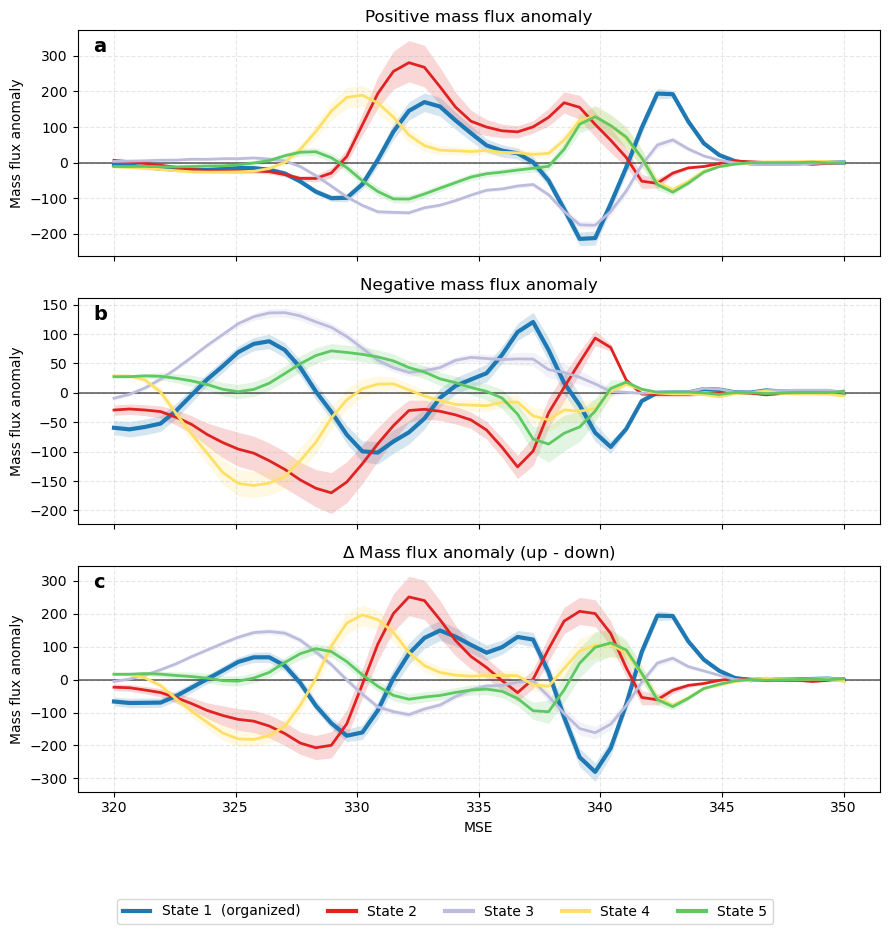

In [7]:
# MSE profiles (same decomposition, plotted against MSE)
mf_pos  = np.clip(mass_flux, 0.0, None)
mf_neg  = np.clip(mass_flux, None, 0.0)
mf_diff = mf_pos + mf_neg
mf_fields = [(mf_pos,  'Positive mass flux anomaly'),
             (mf_neg,  'Negative mass flux anomaly'),
             (mf_diff, r'$\Delta$ Mass flux anomaly (up - down)')]

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, (mf, title), lbl in zip(axes, mf_fields, ['a', 'b', 'c']):
    mf_sum       = mf.sum(axis=1)
    mean_profile = mf_sum.mean(axis=0)
    ax.axhline(0.0, color='k', lw=1.2, alpha=0.6)
    for s in range(NUM_STATES):
        idxs = state_keep_indices_mf.get(s)
        if idxs is None or len(idxs) == 0:
            continue
        mean_p, lo_p, hi_p = wfp.bootstrap_profile_band(
            mf_sum[idxs] - mean_profile[None, :], n_boot=400, ci=0.90, seed=s)
        ax.fill_between(s_array, wfp.smooth_1d(lo_p, win), wfp.smooth_1d(hi_p, win),
                        color=state_colors[s], alpha=0.18, linewidth=0)
        lw = 3.0 if s == ORG_STATE else 2.0
        ax.plot(s_array, wfp.smooth_1d(mean_p, win), color=state_colors[s], lw=lw)
    ax.set_title(title); ax.set_ylabel('Mass flux anomaly')
    ax.grid(True, linestyle='--', alpha=0.3); wfp.panel_label(ax, lbl)
axes[-1].set_xlabel('MSE')
leg = fig.legend(handles=handles, loc='lower center', ncol=NUM_STATES, frameon=True,
                 bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(os.path.join(path_save_fig, 'q2_mse_profiles.pdf'), bbox_inches='tight')
plt.show()

## Q3 · Eigenvectors — is λ₂ still a two-regime split?

Eigenvalue spectrum and relaxation times of the transition matrix, then the leading
non-stationary right eigenvectors v₂ and v₃ as **plain unit-norm** amplitudes per cluster
(np.linalg.eig returns unit-norm columns; we do not rescale to max = 1). A clean sign split in
v₂ means λ₂ encodes a two-regime (e.g. organized vs unorganized) slow mode.

In [8]:
DT_CHAIN_MIN = 5 * 2  # raw dt = 2 min, future=5 -> 10 min per chain step
eigvals, eigvecs = wfp.eigendecomposition(Tmat)
tau = wfp.relaxation_times(eigvals, DT_CHAIN_MIN)

print('=' * 64)
print(f"Eigenvalue spectrum (chain step dt = {DT_CHAIN_MIN} min)")
print('=' * 64)
print(f"{'k':>3}  {'lambda_k':<20}  {'|lambda|':>8}  {'tau_k':>16}")
print('-' * 64)
for k in range(NUM_STATES):
    lam = eigvals[k]
    lam_str = (f"{lam.real:+.4f}{lam.imag:+.4f}j" if abs(lam.imag) > 1e-9
               else f"{lam.real:+.4f}")
    tau_str = 'inf (stationary)' if k == 0 else f"{tau[k]:>6.1f} min ({tau[k]/60:.2f} h)"
    print(f"{k+1:>3}  {lam_str:<20}  {abs(lam):>8.4f}  {tau_str:>16}")

print('\nStationary distribution pi:')
for s in range(NUM_STATES):
    print(f"  State {wfp.state_label(s)}:  pi = {pi[s]:.4f}")

for kk, name in [(1, 'v_2 (leading non-stationary mode)'),
                 (2, 'v_3 (subleading mode)')]:
    v = np.real(eigvecs[:, kk])   # unit-norm as returned by eig; NOT rescaled
    print(f"\nRight eigenvector {name} - unit-norm amplitudes by cluster")
    for s in range(NUM_STATES):
        bar = ('+' * max(1, int(round(30 * abs(v[s]))))) if v[s] > 0 \
              else ('-' * max(1, int(round(30 * abs(v[s])))))
        print(f"  State {wfp.state_label(s)}: {v[s]:+.3f}   {bar}")

Eigenvalue spectrum (chain step dt = 10 min)
  k  lambda_k              |lambda|             tau_k
----------------------------------------------------------------
  1  +1.0000                 1.0000  inf (stationary)
  2  +0.9437                 0.9437   172.4 min (2.87 h)
  3  +0.9020                 0.9020    97.0 min (1.62 h)
  4  +0.8479                 0.8479    60.6 min (1.01 h)
  5  +0.6761                 0.6761    25.6 min (0.43 h)

Stationary distribution pi:
  State 1:  pi = 0.1286
  State 2:  pi = 0.1220
  State 3:  pi = 0.3704
  State 4:  pi = 0.2275
  State 5:  pi = 0.1515

Right eigenvector v_2 (leading non-stationary mode) - unit-norm amplitudes by cluster
  State 1: -0.553   -----------------
  State 2: -0.311   ---------
  State 3: -0.244   -------
  State 4: +0.648   +++++++++++++++++++
  State 5: +0.343   ++++++++++

Right eigenvector v_3 (subleading mode) - unit-norm amplitudes by cluster
  State 1: -0.305   ---------
  State 2: +0.937   ++++++++++++++++++++++++++

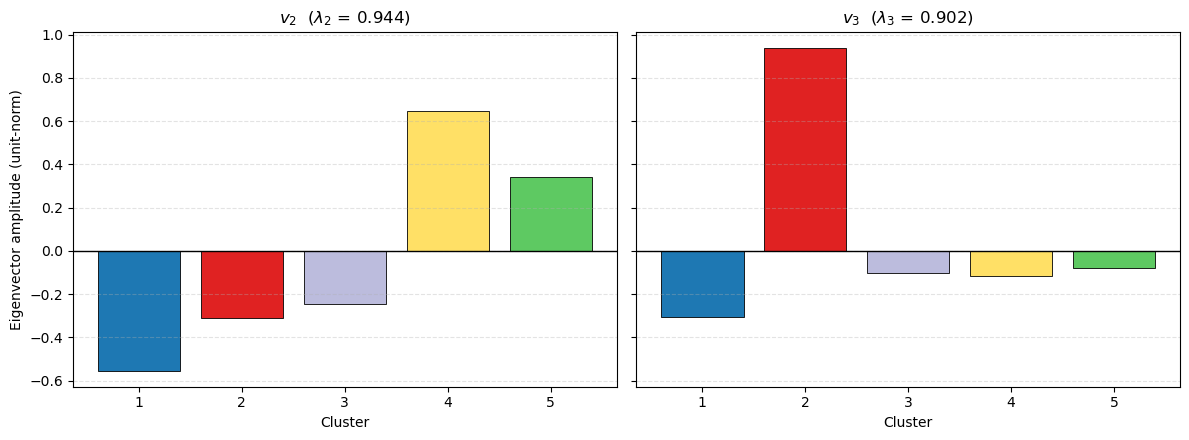

v2 sign split  ->  + : ['4', '5']   - : ['1', '2', '3']


In [9]:
# Bar chart of v2 / v3 amplitudes per cluster (unit-norm)
v2 = np.real(eigvecs[:, 1])
v3 = np.real(eigvecs[:, 2])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, v, k in zip(axes, (v2, v3), (2, 3)):
    ax.bar(range(NUM_STATES), v, color=state_colors, edgecolor='k', linewidth=0.6)
    ax.axhline(0, color='k', lw=1)
    ax.set_xticks(range(NUM_STATES))
    ax.set_xticklabels([wfp.state_label(s) for s in range(NUM_STATES)])
    ax.set_xlabel('Cluster'); ax.set_title(f"$v_{k}$  ($\\lambda_{k}$ = {eigvals[k-1].real:.3f})")
    ax.grid(True, axis='y', linestyle='--', alpha=0.35)
axes[0].set_ylabel('Eigenvector amplitude (unit-norm)')
plt.tight_layout()
plt.savefig(os.path.join(path_save_fig, 'q3_eigenvectors.pdf'), bbox_inches='tight')
plt.show()

pos = [s for s in range(NUM_STATES) if v2[s] > 0]
neg = [s for s in range(NUM_STATES) if v2[s] < 0]
print('v2 sign split  ->  + :', [wfp.state_label(s) for s in pos],
      '  - :', [wfp.state_label(s) for s in neg])

## Q4 · Non-Markovianity of the organized cluster

Per-cluster indicator autocorrelation (solid) vs the Markov-chain prediction (dashed). A cluster
whose empirical curve sits **above** its dashed prediction retains memory the Markov partition
does not capture. We report the RMSE gap per cluster and highlight the organized one.

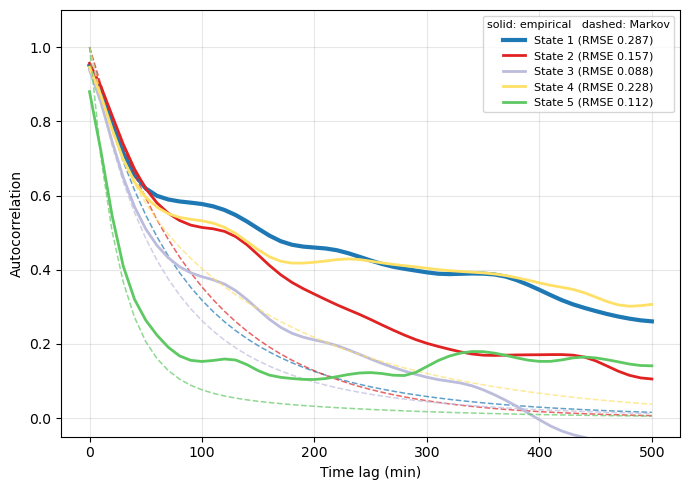

Non-Markovianity RMSE (empirical vs Markov), descending:
  State 1: RMSE = 0.2868  <- organized
  State 4: RMSE = 0.2279
  State 2: RMSE = 0.1567
  State 5: RMSE = 0.1125
  State 3: RMSE = 0.0881


In [10]:
DT_LAG_MIN = 10
n_lag      = C_obs.shape[1]
lags_min   = np.arange(n_lag) * DT_LAG_MIN

fig, ax = plt.subplots(figsize=(7, 5))
gaps = {}
for i in range(NUM_STATES):
    gaps[i] = float(np.sqrt(np.mean((C_obs[i] - C_markov_per_state[i]) ** 2)))
    lw = 3.0 if i == ORG_STATE else 2.0
    ax.plot(lags_min, wfp.smooth_gaussian(C_obs[i], sigma=1.2), color=state_colors[i], lw=lw,
            label=f"State {wfp.state_label(i)} (RMSE {gaps[i]:.3f})")
    ax.plot(lags_min, C_markov_per_state[i], color=state_colors[i], lw=1.1,
            linestyle='--', alpha=0.7)
ax.set_xlabel('Time lag (min)'); ax.set_ylabel('Autocorrelation')
ax.set_ylim(-0.05, 1.1); ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, title='solid: empirical   dashed: Markov', title_fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(path_save_fig, 'q4_markovianity.pdf'), bbox_inches='tight')
plt.show()

print('Non-Markovianity RMSE (empirical vs Markov), descending:')
for s in sorted(gaps, key=gaps.get, reverse=True):
    tag = '  <- organized' if s == ORG_STATE else ''
    print(f"  State {wfp.state_label(s)}: RMSE = {gaps[s]:.4f}{tag}")

## Q4b · Transition matrix & Markov chain in latent space

Left: the latent PCA plane with each cluster drawn as a bubble sized by its stationary weight π
and Bezier arrows for the dominant inter-cluster transition probabilities. Right: the full 5×5
transition matrix P(i → j) (chain step Δt = 10 min) as a log-scale heatmap. No states are
excluded from the arrows (the 7-state paper hid States 1 & 5; here we show all).

/var/folders/1g/zpcrn7ys4y15p92_t65w5_200000gn/T/ipykernel_4011/1124197571.py:55: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(os.path.join(path_save_fig, 'q4b_markov_matrix.pdf'),
/var/folders/1g/zpcrn7ys4y15p92_t65w5_200000gn/T/ipykernel_4011/1124197571.py:55: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(os.path.join(path_save_fig, 'q4b_markov_matrix.pdf'),
/opt/anaconda3/envs/samenv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


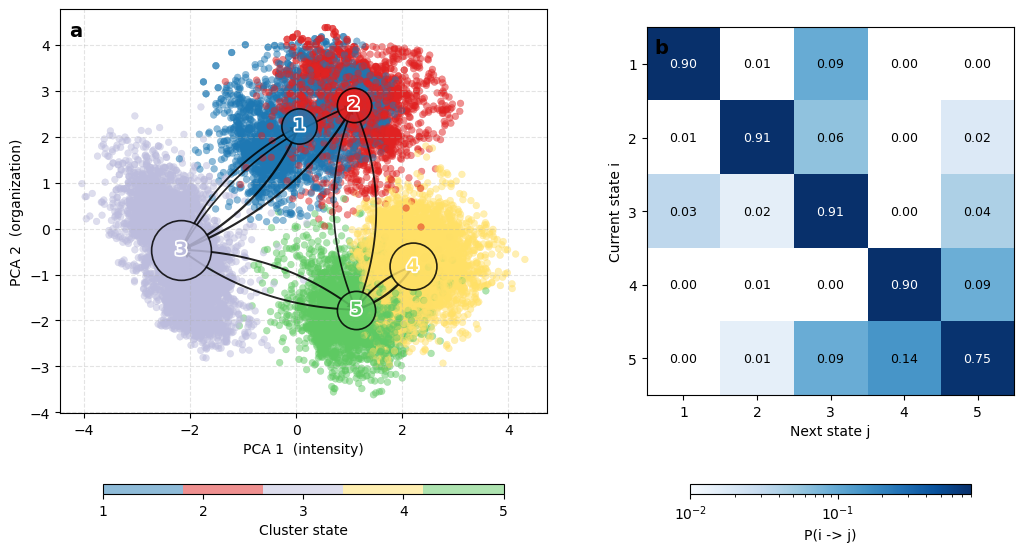

Transition matrix P(i->j), 10-min step (rows = current i, cols = next j):
            1      2      3      4      5
  i=1:  0.897  0.009  0.094  0.000  0.000
  i=2:  0.006  0.912  0.060  0.003  0.018
  i=3:  0.034  0.015  0.909  0.001  0.042
  i=4:  0.000  0.008  0.003  0.901  0.089
  i=5:  0.000  0.015  0.091  0.144  0.750


In [11]:
FIGSIZE      = (14, 7)
BUBBLE_SCALE = 5000
TMIN, TMAX   = 0.01, 0.8
bubble_size  = BUBBLE_SCALE * pi

fig = plt.figure(figsize=FIGSIZE, constrained_layout=True)
gs  = gridspec.GridSpec(100, 100)
ax_pca  = fig.add_subplot(gs[10:85,  6:51])
ax_mat  = fig.add_subplot(gs[10:85, 60:94])
cax_pca = fig.add_subplot(gs[98:100, 10:47])
cax_mat = fig.add_subplot(gs[98:100, 64:90])

# ── (a) Markov chain in latent space ────────────────────────────────────────
sc = ax_pca.scatter(emb_pca[:, 0], emb_pca[:, 1], c=states,
                    cmap=cluster_cmap, norm=norm_state, s=24, alpha=0.5, linewidth=0.25)
ax_pca.set(xlabel='PCA 1  (intensity)', ylabel='PCA 2  (organization)')
ax_pca.grid(True, linestyle='--', alpha=0.35)
wfp.panel_label(ax_pca, 'a')

bary = np.array([emb_pca[states == s].mean(axis=0) if (states == s).any() else np.zeros(2)
                 for s in range(NUM_STATES)])

cbar_pca = fig.colorbar(sc, cax=cax_pca, orientation='horizontal', aspect=60, shrink=0.8)
cbar_pca.set_label('Cluster state')
cbar_pca.set_ticks(np.arange(NUM_STATES))
cbar_pca.set_ticklabels([wfp.state_label(i) for i in range(NUM_STATES)])

# Arrows: show all clusters (override the paper's exclude_states={0,4})
wfp.draw_markov_transitions(ax_pca, Tmat, {s: bary[s] for s in range(NUM_STATES)},
                            min_weight=0.02, min_prob=0.011, exclude_states=frozenset())

for s in range(NUM_STATES):
    ax_pca.scatter(*bary[s], s=bubble_size[s], color=state_colors[s],
                   edgecolors='black', linewidths=1.2, alpha=0.85, zorder=999)
    ax_pca.text(*bary[s], wfp.state_label(s), fontsize=13, fontweight='bold',
                color=state_colors[s], ha='center', va='center', zorder=1000,
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])

# ── (b) Transition matrix heatmap ────────────────────────────────────────────
Tplot    = np.ma.masked_less(Tmat, TMIN)
norm_mat = mcolors.LogNorm(vmin=TMIN, vmax=TMAX)
im = ax_mat.imshow(Tplot, cmap='Blues', norm=norm_mat, origin='upper')
ax_mat.set(xlabel='Next state j', ylabel='Current state i')
ax_mat.set_xticks(np.arange(NUM_STATES)); ax_mat.set_yticks(np.arange(NUM_STATES))
ax_mat.set_xticklabels([wfp.state_label(i) for i in range(NUM_STATES)])
ax_mat.set_yticklabels([wfp.state_label(i) for i in range(NUM_STATES)])
wfp.panel_label(ax_mat, 'b')
for i in range(NUM_STATES):
    for j in range(NUM_STATES):
        ax_mat.text(j, i, f"{Tmat[i, j]:.2f}", ha='center', va='center', fontsize=9,
                    color='white' if Tmat[i, j] > 0.5 * Tmat.max() else 'black')
fig.colorbar(im, cax=cax_mat, orientation='horizontal', aspect=60,
             shrink=0.8).set_label('P(i -> j)')

plt.savefig(os.path.join(path_save_fig, 'q4b_markov_matrix.pdf'),
            bbox_inches='tight', pad_inches=0.05)
plt.show()

# Bubble = stationary weight; arrows = dominant transitions. Print the matrix too.
print('Transition matrix P(i->j), 10-min step (rows = current i, cols = next j):')
hdr = '       ' + ' '.join(f"{wfp.state_label(j):>6}" for j in range(NUM_STATES))
print(hdr)
for i in range(NUM_STATES):
    print(f"  i={wfp.state_label(i)}: " + ' '.join(f"{Tmat[i, j]:>6.3f}" for j in range(NUM_STATES)))

## Summary

Run all cells above, then read the printed diagnostics:

- **Q1** — `corr(PC1, precip)` and `corr(PC2, PW)` quantify whether the intensity / organization
  plane survives at 5 clusters.
- **Q2** — the thick (organized) line in the net mass-flux panel shows whether the organized
  cluster has the expected deep coherent updraft.
- **Q3** — the v₂ sign split printed at the end of the eigenvector cell tells you whether λ₂ is
  still a two-regime mode.
- **Q4** — the RMSE table ranks clusters by residual (non-Markovian) memory; check whether the
  organized cluster tops it.